## Fase 1: Exploración Inicial

1. Importen el CSV usando pandas.
2. Utilicen StandardScaler sobre las columnas Latitud y Longitud y guarden la matriz escalada (X_scaled). Recuerden: un grado de longitud no mide exactamente los mismos kilómetros que un grado de latitud. Escalar nivela el terreno matemático.
3. Grafiquen los datos crudos usando un Scatter Plot (Longitud en el eje X, Latitud en el eje Y). Si lo hacen correctamente, deberían ver la silueta de la costa del Pacífico.


In [9]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler


df = pd.read_csv("logistica_baja_california.csv")
df.head(10)


,Latitud,Longitud,Tipo_Solicitud
0,32.520796,-116.992084,Recoleccion
1,32.566198,-117.046102,Recoleccion
2,32.461507,-117.062417,Viaje_Pasajero
3,32.510667,-117.023516,Viaje_Pasajero
4,32.498468,-117.019210,Viaje_Pasajero
5,32.536176,-117.031669,Entrega_Paquete
6,32.490330,-117.061402,Recoleccion
7,32.546237,-117.060305,Viaje_Pasajero
8,32.526208,-117.047032,Entrega_Paquete
9,32.527172,-117.021078,Viaje_Pasajero


In [10]:
df_logistica_bc = df[["Latitud", "Longitud"]]

scaler = StandardScaler()

X_matrix = scaler.fit_transform(df_logistica_bc)
print(X_matrix)

[[ 0.88335238 -0.73514142]
 [ 1.00618974 -0.94540065]
 [ 0.72294016 -1.00890342]
 ...
 [-4.40047914  3.45447951]
 [-4.3579893   3.2636921 ]
 [-4.41124399  3.35464997]]


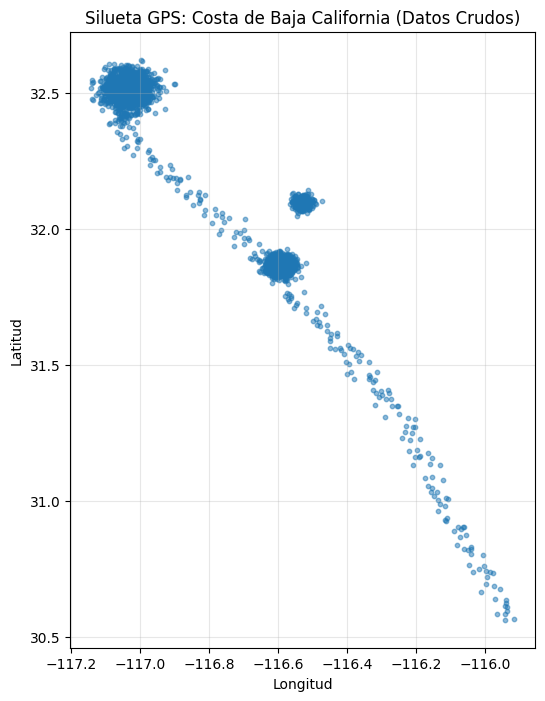

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 8))
plt.scatter(
    df["Longitud"], df["Latitud"], s=10, alpha=0.5
)

plt.title("Silueta GPS: Costa de Baja California (Datos Crudos)")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.grid(True, alpha=0.3)
plt.show()

## Fase 2: Misión Estratégica
La mesa directiva aprobó el presupuesto para construir 3 grandes Centros de Distribución (Cedis) en el estado. Necesitan saber exactamente dónde ubicarlos para que queden en el centro geográfico de la demanda general, minimizando los kilómetros de viaje hacia cualquier punto.

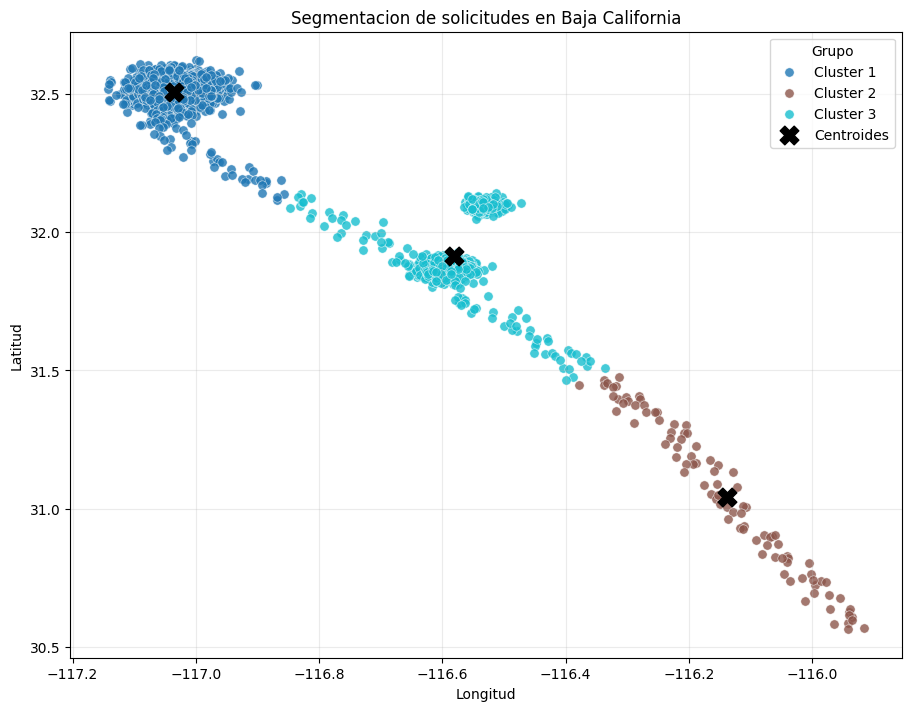

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

numero_clusters = 3
modelo_kmeans = KMeans(n_clusters=numero_clusters, random_state=42, n_init=10)
etiquetas_cluster = modelo_kmeans.fit_predict(X_matrix)
centroides = scaler.inverse_transform(modelo_kmeans.cluster_centers_)

fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)
colores = plt.get_cmap("tab10", numero_clusters)

for cluster in range(numero_clusters):
    seleccion = etiquetas_cluster == cluster
    ax.scatter(
        df_logistica_bc.loc[seleccion, "Longitud"],
        df_logistica_bc.loc[seleccion, "Latitud"],
        color=colores(cluster),
        label=f"Cluster {cluster + 1}",
        s=45,
        alpha=0.8,
        edgecolors="white",
        linewidths=0.4,
    )

ax.scatter(
    centroides[:, 1],
    centroides[:, 0],
    color="black",
    marker="X",
    s=180,
    label="Centroides",
    zorder=3,
)
ax.set_title("Segmentacion de solicitudes en Baja California")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.grid(True, alpha=0.25)
ax.legend(title="Grupo", loc="best")
plt.show()

### Pregunta de Análisis

1. ¿Qué algoritmo de los vistos en clase se adecua mas a este problema?

K-means (n_clusters=3)

2. ¿Dónde colocó el algoritmo que seleccionaron las Cedis?

K-Means colocó una Cedis en Tijuana, otra cerca de Ensenada/Valle G., y la tercera a mitad de camino en la carretera hacia el sur para compensar la presencia de San Quintín.

3. ¿Consideran que sus localizaciones hacen sentido?

No tienen tanto sentido para la demanda urbana densa, porque la tercera Cedis queda "jalada" hacia una zona semirural dispersa debido al peso de los puntos de San Quintín en el cálculo del centroide.

4. ¿Por que la matematica de este algoritmo provoco esto?

K-Means minimiza la suma de distancias al cuadrado (inercia). Como San Quintín está muy alejado (outlier), la matemática fuerza a mover un centroide hacia el sur para minimizar el error global.

## Fase 3: Misión Operativa (Mapa de Tráfico y Zonas Calientes)
Los choferes se están quejando de que hacen viajes de 2 horas para entregar un solo paquete a un rancho aislado en la carretera (ruido/anomalías), alejándolos de la zona urbana donde hay dinero. Necesitan un mapa táctico que aísle las ciudades principales (Alta Densidad) y descarte matemáticamente las zonas rurales dispersas.

C:\Users\jumbo\AppData\Local\Temp\ipykernel_12712\1263013298.py:24: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colores = plt.cm.get_cmap("tab10", len(clusters_unicos))


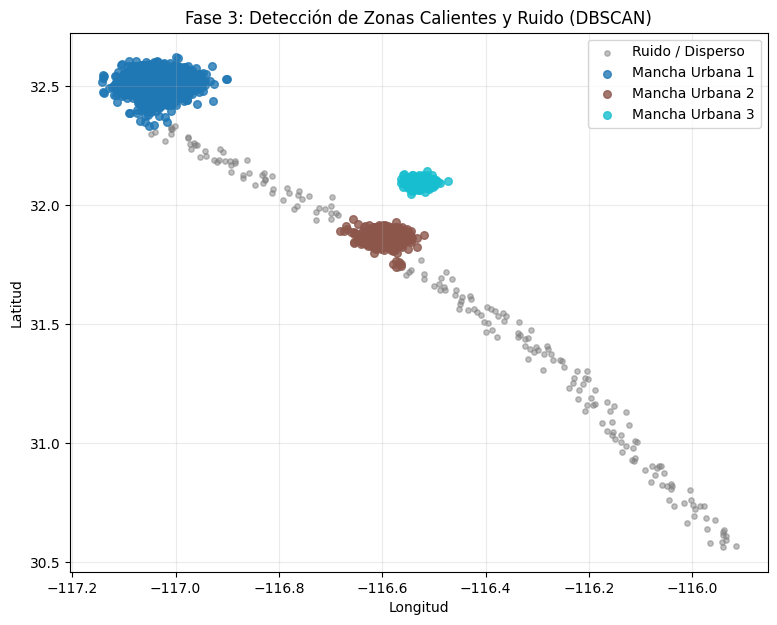

In [ ]:
from sklearn.cluster import DBSCAN

# seleccionar el algoritmo adecuado para densidad y ruido (DBSCAN)
dbscan = DBSCAN(eps=0.15, min_samples=25)
etiquetas_dbscan = dbscan.fit_predict(X_matrix)

# graficar los resultados separando el ruido
plt.figure(figsize=(9, 7))

# puntos de ruido (Cluster -1)
ruido = etiquetas_dbscan == -1
plt.scatter(
    df_logistica_bc.loc[ruido, "Longitud"],
    df_logistica_bc.loc[ruido, "Latitud"],
    color="grey",
    alpha=0.5,
    s=15,
    label="Ruido / Disperso",
)

clusters_unicos = set(etiquetas_dbscan) - {-1}
colores = plt.cm.get_cmap("tab10", len(clusters_unicos))

for i, cluster_id in enumerate(clusters_unicos):
    seleccion = etiquetas_dbscan == cluster_id
    plt.scatter(
        df_logistica_bc.loc[seleccion, "Longitud"],
        df_logistica_bc.loc[seleccion, "Latitud"],
        color=colores(i),
        alpha=0.8,
        s=30,
        label=f"Mancha Urbana {cluster_id + 1}",
    )

plt.title("Fase 3: Detección de Zonas Calientes y Ruido (DBSCAN)")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.grid(True, alpha=0.25)
plt.legend()
plt.show()

### Pregunta de Análisis

1. ¿Usaron el mismo algoritmo que en la misión anterior?

Se cambió de K-means a DBSCAN, preferimos observar la gráfica por medio de densidad en vez de centroides, ya que no clasifica adecuadamente la separación entre las distintas ciudades.

2. ¿De no ser así, porqué se comportaron diferentes?

K-means asigna el 100% de los puntos a algún grupo sin importar la distancia, mientras DBSCAN agrupa por densidad de puntos vecinos, si un punto no cumple con la densidad mínima requerida en su vecindario, lo clasifica como ruido.

3. ¿A qué ciudades reales corresponden las 3 manchas urbanas que encontró su algoritmo?

Tijuana, Valle de Guadalupe y Ensenada, y San Quintin fue considerado como el ruido de la carretera, mientras DBSCAN separa de forma natural la densidad de las 3 ciudades reales.
